
# Quantitative Portfolio Management Platform

## Objective
Build and evaluate diversified investment portfolios using
historical market data, portfolio optimization, and risk analytics.

## Research questions
1. How does optimization change asset allocation?
2. Does optimization improve risk adjusted performance?
3. How sensitive are results to transaction costs?
4. How does the portfolio behave during market declines?

## Disclaimer
This project is for educational research only.
Historical performance does not guarantee future results.
      

In [12]:

!pip -q install yfinance scipy PyPortfolioOpt plotly quantstats


In [13]:

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import plotly.express as px

from scipy.optimize import minimize

pd.set_option("display.max_columns", None)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [14]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

tickers = ["SPY", "QQQ", "IEF", "GLD", "VNQ"]

raw_data = yf.download(
    tickers,
    period="5y",
    auto_adjust=True,
    progress=False
)

if raw_data.empty:
    raise ValueError(
        "No data downloaded. Check your internet connection and try again."
    )

# Extract closing prices, including MultiIndex data
if isinstance(raw_data.columns, pd.MultiIndex):
    if "Close" in raw_data.columns.get_level_values(0):
        prices = raw_data["Close"]
    elif "Close" in raw_data.columns.get_level_values(1):
        prices = raw_data.xs("Close", axis=1, level=1)
    else:
        raise ValueError("Could not find closing prices.")
else:
    prices = raw_data["Close"]

# Keep the requested assets in the correct order
prices = prices.reindex(columns=tickers)

print("Downloaded price data successfully.")
print("Dataset shape:", prices.shape)
display(prices.head())

Downloaded price data successfully.
Dataset shape: (1255, 5)


Ticker,SPY,QQQ,IEF,GLD,VNQ
Date,,,,,
2021-10-11,406.566620,347.836823,97.904587,163.919998,84.842125
2021-10-12,405.565826,346.623627,98.350555,164.660004,85.953377
2021-10-13,407.024933,349.399475,98.539253,167.589996,86.578949
2021-10-14,413.871307,355.834137,98.770813,168.000000,87.632591
2021-10-15,417.023285,358.076202,98.281914,165.330002,87.566719


In [15]:
# Remove duplicate dates and sort chronologically
prices = prices[~prices.index.duplicated(keep="last")]
prices = prices.sort_index()

# Keep only assets with complete price histories
prices = prices.dropna(axis=1, how="any")

if prices.shape[1] < 2:
    raise ValueError(
        "Fewer than two complete assets. Rerun Step 4 or check the data."
    )

tickers = prices.columns.tolist()

print("Assets available:", tickers)
print("Missing values:", prices.isna().sum().sum())
print("First date:", prices.index.min())
print("Last date:", prices.index.max())
print("Number of observations:", len(prices))

display(prices.head())

Assets available: ['SPY', 'QQQ', 'IEF', 'GLD', 'VNQ']
Missing values: 0
First date: 2021-10-11 00:00:00
Last date: 2026-10-09 00:00:00
Number of observations: 1255


Ticker,SPY,QQQ,IEF,GLD,VNQ
Date,,,,,
2021-10-11,406.566620,347.836823,97.904587,163.919998,84.842125
2021-10-12,405.565826,346.623627,98.350555,164.660004,85.953377
2021-10-13,407.024933,349.399475,98.539253,167.589996,86.578949
2021-10-14,413.871307,355.834137,98.770813,168.000000,87.632591
2021-10-15,417.023285,358.076202,98.281914,165.330002,87.566719


In [16]:

returns = prices.pct_change(fill_method=None).dropna()

# Remove any invalid return observations
returns = returns.replace([np.inf, -np.inf], np.nan).dropna()

if returns.empty:
    raise ValueError("No valid returns. Check the downloaded prices.")

    print("Return data shape:", returns.shape)
    display(returns.head())

    print("Average daily returns:")
    display(returns.mean().round(6))

    print("Daily volatility:")
    display(returns.std().round(6))


In [17]:
def calculate_metrics(daily_returns, risk_free_rate=0.0):
    r = daily_returns.dropna()

    if len(r) < 2:
        raise ValueError("At least two return observations are required.")

    wealth = (1 + r).cumprod()
    annual_return = wealth.iloc[-1] ** (252 / len(r)) - 1
    annual_volatility = r.std(ddof=1) * np.sqrt(252)

    daily_rf = (1 + risk_free_rate) ** (1 / 252) - 1
    excess_returns = r - daily_rf

    sharpe = (
        excess_returns.mean() / r.std(ddof=1) * np.sqrt(252)
        if r.std(ddof=1) > 0 else np.nan
    )

    drawdown = wealth / wealth.cummax() - 1
    var_95 = r.quantile(0.05)
    tail_returns = r[r <= var_95]

    return {
        "Annualized Return": annual_return,
        "Annualized Volatility": annual_volatility,
        "Sharpe Ratio": sharpe,
        "Maximum Drawdown": drawdown.min(),
        "Daily VaR 95%": -var_95,
        "Daily Expected Shortfall 95%": -tail_returns.mean()
    }

# Compute equal-weighted returns across the available assets
equal_returns = returns.mean(axis=1)
equal_metrics = calculate_metrics(equal_returns)

display(pd.Series(equal_metrics).to_frame("Equal Weighted"))

,Equal Weighted
Annualized Return,0.103731
Annualized Volatility,0.123435
Sharpe Ratio,0.861327
Maximum Drawdown,-0.235029
Daily VaR 95%,0.012215
Daily Expected Shortfall 95%,0.017632


Optimized Portfolio Weights:
SPY: 0.4679
QQQ: 0.0000
IEF: 0.0000
GLD: 0.5321
VNQ: 0.0000



,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Daily VaR 95%,Daily Expected Shortfall 95%
Equal Weighted,0.1037,0.1234,0.8613,-0.2350,0.0122,0.0176
Optimized In Sample,0.1725,0.1382,1.2208,-0.1784,0.0129,0.0203


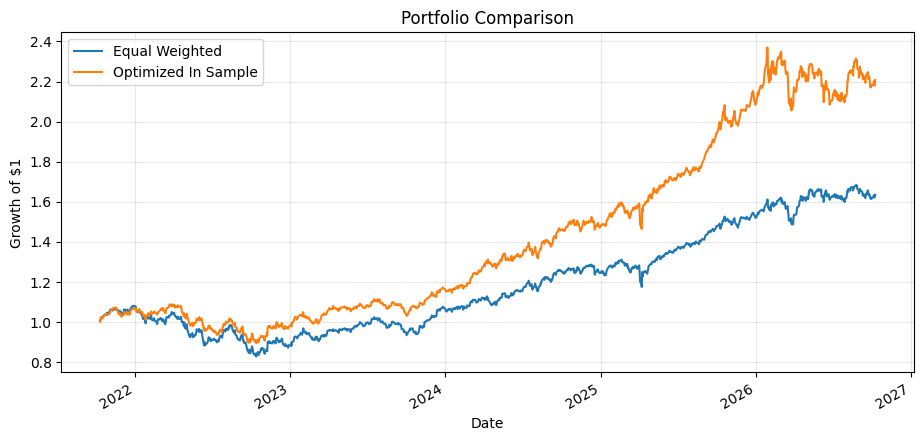

In [18]:
# Calculate mean daily returns and covariance matrix
mean_returns = returns.mean()
cov_matrix = returns.cov()

# Objective function: minimize negative Sharpe ratio
def negative_sharpe(weights, mean_returns, cov_matrix, risk_free_rate=0.0):
    p_return = np.sum(mean_returns * weights) * 252
    p_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix * 252, weights)))
    return -(p_return - risk_free_rate) / p_vol

# Constraints and bounds
num_assets = len(tickers)
constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
bounds = tuple((0.0, 1.0) for _ in range(num_assets))
initial_weights = np.array(num_assets * [1.0 / num_assets])

# Optimize weights
opt_results = minimize(
    negative_sharpe,
    initial_weights,
    args=(mean_returns, cov_matrix),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

weights_opt = opt_results.x
print("Optimized Portfolio Weights:")
for t, w in zip(tickers, weights_opt):
    print(f"{t}: {w:.4f}")
print()

optimized_returns = returns @ weights_opt

comparison = pd.DataFrame({
    "Equal Weighted": calculate_metrics(equal_returns),
    "Optimized In Sample": calculate_metrics(optimized_returns)
}).T

display(comparison.round(4))

wealth_comparison = pd.DataFrame({
    "Equal Weighted": (1 + equal_returns).cumprod(),
    "Optimized In Sample": (1 + optimized_returns).cumprod()
})

wealth_comparison.plot(figsize=(11, 5), title="Portfolio Comparison")
plt.ylabel("Growth of $1")
plt.grid(alpha=0.3)
plt.show()

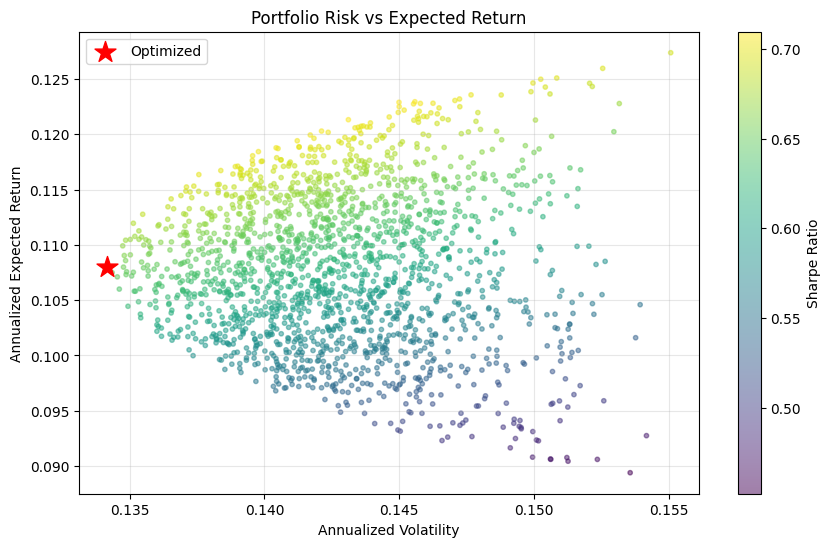

Feasible portfolios plotted: 1813


In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- 1. Define inputs (replace these with your actual data) ---
n_assets = 5
max_weight = 0.40  # Maximum weight constraint per asset
risk_free_rate = 0.02  # Risk-free rate for Sharpe ratio calculation

mean_returns = pd.Series([0.10, 0.12, 0.08, 0.15, 0.09])
cov_matrix = pd.DataFrame(np.eye(n_assets) * 0.04 + 0.01)
weights_opt = np.array([0.2, 0.2, 0.2, 0.2, 0.2])  # Optimized weights

# --- 2. Monte Carlo Simulation ---
rng = np.random.default_rng(42)
n_simulations = 5000

simulated_weights = rng.dirichlet(np.ones(n_assets), size=n_simulations)

# Apply the maximum weight constraint
mask = simulated_weights.max(axis=1) <= max_weight
simulated_weights = simulated_weights[mask]

if len(simulated_weights) == 0:
  raise ValueError(
      "No portfolios satisfied the max_weight constraint. Try increasing"
      " max_weight."
  )

# --- 3. Compute Portfolio Metrics ---
# Convert pandas objects to NumPy arrays for safe, high-performance matrix math
returns_arr = mean_returns.to_numpy()
cov_arr = cov_matrix.to_numpy()
opt_weights_arr = (
    weights_opt.to_numpy()
    if hasattr(weights_opt, "to_numpy")
    else np.asarray(weights_opt)
)

sim_returns = simulated_weights @ returns_arr

sim_volatility = np.sqrt(
    np.einsum("ij,jk,ik->i", simulated_weights, cov_arr, simulated_weights)
)

# --- 4. Plotting ---
plt.figure(figsize=(10, 6))

# Calculate Sharpe ratio incorporating the risk-free rate
sharpe_ratios = (sim_returns - risk_free_rate) / np.maximum(
    sim_volatility, 1e-10
)

sc = plt.scatter(
    sim_volatility,
    sim_returns,
    c=sharpe_ratios,
    cmap="viridis",
    s=10,
    alpha=0.5,
)
plt.colorbar(sc, label="Sharpe Ratio")

# Compute metrics for the optimized portfolio
opt_vol = np.sqrt(opt_weights_arr @ cov_arr @ opt_weights_arr)
opt_return = opt_weights_arr @ returns_arr

plt.scatter(
    opt_vol, opt_return, marker="*", s=250, color="red", label="Optimized"
)
plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Expected Return")
plt.title("Portfolio Risk vs Expected Return")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Feasible portfolios plotted:", len(sim_returns))

,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Daily VaR 95%,Daily Expected Shortfall 95%
Equal Weighted,0.1037,0.1234,0.8613,-0.2350,0.0122,0.0176
Optimized In Sample,0.1725,0.1382,1.2208,-0.1784,0.0129,0.0203
SPY Benchmark,0.1395,0.1715,0.8471,-0.2450,0.0165,0.0246


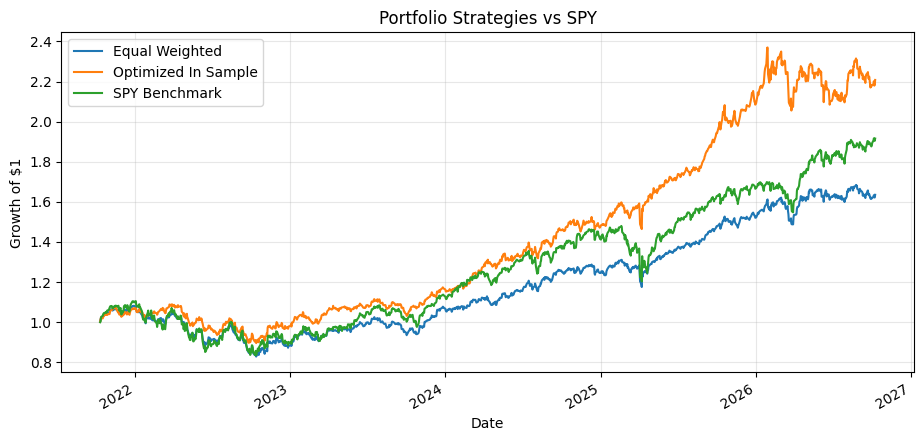

In [24]:

benchmark = returns["SPY"]

# Compare over the same dates
comparison_with_benchmark = pd.DataFrame({
    "Equal Weighted": equal_returns,
    "Optimized In Sample": optimized_returns,
    "SPY Benchmark": benchmark
}).dropna()

display(pd.DataFrame({
    name: calculate_metrics(comparison_with_benchmark[name])
    for name in comparison_with_benchmark.columns
}).T.round(4))

comparison_with_benchmark.add(1).cumprod().plot(
    figsize=(11, 5),
    title="Portfolio Strategies vs SPY"
)
plt.ylabel("Growth of $1")
plt.grid(alpha=0.3)
plt.show()

In [21]:

lookback = 252
transaction_cost = 0.001  # 0.10% per dollar traded

backtest_returns = []
backtest_dates = []
current_weights = None
previous_month = None

for i in range(lookback, len(returns)):
    date = returns.index[i]

    # Estimate weights using past returns only
    if date.month != previous_month:
        history = returns.iloc[i - lookback:i]
        mu = history.mean().to_numpy() * 252
        sigma = history.cov().to_numpy() * 252
        sigma += np.eye(n_assets) * 1e-8

        def objective(w):
            vol = np.sqrt(max(w @ sigma @ w, 0))
            if vol < 1e-10:
                return 1e6
            return -(w @ mu) / vol

        fit = minimize(
            objective,
            np.repeat(1 / n_assets, n_assets),
            method="SLSQP",
            bounds=[(0, max_weight)] * n_assets,
            constraints=[
                {"type": "eq", "fun": lambda w: w.sum() - 1}
            ]
        )

        if not fit.success:
            raise ValueError(
                f"Optimization failed for rebalance date {date}"
            )

        target_weights = fit.x

        if current_weights is None:
            # Initial portfolio setup
            current_weights = target_weights.copy()
            cost = 0.0
        else:
            # Approximate turnover based on pre-trade weights
            turnover = np.abs(
                target_weights - current_weights
            ).sum()

            cost = transaction_cost * turnover
            current_weights = target_weights.copy()

        previous_month = date.month
    else:
        cost = 0.0

    # Apply today's returns to weights estimated from prior data
    daily_portfolio_return = (
        current_weights @ returns.iloc[i].to_numpy()
    )

    # Deduct rebalance costs on the rebalance date
    daily_portfolio_return -= cost

    backtest_returns.append(daily_portfolio_return)
    backtest_dates.append(date)

backtest = pd.Series(
    backtest_returns,
    index=backtest_dates,
    name="Rolling Optimized Net"
)

print("Backtest observations:", len(backtest))
display(pd.Series(calculate_metrics(backtest)))

Backtest observations: 1002


,0
Annualized Return,0.230293
Annualized Volatility,0.122867
Sharpe Ratio,1.748730
Maximum Drawdown,-0.094983
Daily VaR 95%,0.011411
Daily Expected Shortfall 95%,0.016577


In [22]:
# Define allocation DataFrame using the optimized weights
allocation = pd.DataFrame({
    "Ticker": tickers,
    "Optimized Weight": weights_opt
})

# Export results to CSV files
allocation.to_csv("portfolio_allocations.csv", index=False)
comparison.to_csv("in_sample_comparison.csv")
backtest.to_csv("rolling_backtest_returns.csv")

print("Exported portfolio allocations, comparison metrics, and backtest returns.")

# Trigger automatic downloads of the exported CSV files
try:
    from google.colab import files
    files.download("portfolio_allocations.csv")
    files.download("in_sample_comparison.csv")
    files.download("rolling_backtest_returns.csv")
    print("Triggered automatic file downloads.")
except ImportError:
    print("Not running in Google Colab; files saved locally.")

Exported portfolio allocations, comparison metrics, and backtest returns.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Triggered automatic file downloads.
